<a href="https://colab.research.google.com/github/Simonguz/MOCOS/blob/main/MOCOS_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Часть 1. Исследование эффектов дискретизации

### Задание 1

Определить допустимые значения частоты дискретизации $f_s$ для конечного сигнала, представляющего собой сумму двух синусоид с разными частотами:

$$
x(t)=
\begin{cases}
\sin(2\pi\nu_1t)+\sin(2\pi\nu_2t), & t\in[0;1],\\
0, & t\notin[0;1],
\end{cases}
$$

где $t$ — время в секундах.

Для варианта 6:

$$
\nu_1=32\text{ Гц},\qquad \nu_2=69\text{ Гц}.
$$

### Решение

Подставим частоты своего варианта:

$$
x(t)=
\begin{cases}
\sin(64\pi t)+\sin(138\pi t), & t\in[0;1],\\
0, & t\notin[0;1].
\end{cases}
$$

Максимальная частота двух гармонических составляющих:

$$
F_{\max}=\max(\nu_1,\nu_2)=\max(32,69)=69\text{ Гц}.
$$

По принятому в задании частотному критерию частота дискретизации должна удовлетворять условию:

$$
f_s>2F_{\max}.
$$

Следовательно,

$$
\boxed{f_s>138\text{ Гц}.}
$$

Поскольку период дискретизации связан с частотой соотношением
$\Delta t=1/f_s$, получаем:

$$
\boxed{
0<\Delta t<\frac{1}{138}\approx0{,}007246\text{ с}
=7{,}246\text{ мс}.
}
$$

**Вывод:** по частотам заданных гармоник выбираем частоту дискретизации выше 138 Гц. Если частота задаётся целым числом герц, минимальное значение, удовлетворяющее этому условию, — 139 Гц.

**Уточнение:** строго говоря, ограничение сигнала интервалом $[0;1]$ расширяет его спектр до бесконечной полосы. Поэтому условие $f_s>138$ Гц относится к двум исходным гармоникам и не гарантирует абсолютно точного восстановления всего ограниченного по времени сигнала.

### Задание 2

Выполнить дискретизацию сигнала $x(t)$ с частотами:

$$
f_1=f_0-10,\qquad f_2=f_0+10,\qquad f_3=f_0+1,
$$

где

$$
f_0=2\max(\nu_1,\nu_2).
$$

### Решение

Для варианта 6 $\nu_1=32$ Гц, $\nu_2=69$ Гц, поэтому:

$$
f_0=2\cdot69=138\text{ Гц}.
$$

Получаем три частоты дискретизации:

$$
f_1=128\text{ Гц},\qquad
f_2=148\text{ Гц},\qquad
f_3=139\text{ Гц}.
$$

При каждой частоте $f_s$ моменты взятия отсчётов определяются формулой:

$$
t_k=k\Delta t=\frac{k}{f_s}.
$$

Значения дискретного сигнала:

$$
x_k=x(t_k)
=\sin\left(\frac{64\pi k}{f_s}\right)
+\sin\left(\frac{138\pi k}{f_s}\right).
$$

Используем отсчёты на интервале $[0;1)$, то есть
$k=0,1,\ldots,f_s-1$ для выбранных целочисленных частот.

Отсчёт при $t=1$ не включаем: его значение равно нулю, поэтому
его отсутствие не изменит сумму при вычислении спектра.

In [14]:
import numpy as np

# Частоты гармоник для варианта 6, Гц
nu1 = 32
nu2 = 69

# Продолжительность сигнала, с
T = 1.0

# Частоты дискретизации по условию
f0 = 2 * max(nu1, nu2)
sampling_frequencies = [f0 - 10, f0 + 10, f0 + 1]


def signal(t):
    """Конечный сигнал: сумма двух синусоид на [0, 1]."""
    values = np.sin(2 * np.pi * nu1 * t) + np.sin(2 * np.pi * nu2 * t)
    return np.where((t >= 0) & (t <= T), values, 0.0)


# Сохраняем результаты для следующих заданий
sampled_signals = {}

for fs in sampling_frequencies:
    dt = 1 / fs

    # Целые номера отсчётов и соответствующие моменты времени
    k = np.arange(int(T * fs))
    t_samples = k / fs

    # Значения сигнала в моменты дискретизации
    x_samples = signal(t_samples)

    sampled_signals[fs] = {
        "dt": dt,
        "t": t_samples,
        "x": x_samples,
    }

    print(
        f"fs = {fs} Гц | "
        f"Δt = {dt:.8f} с | "
        f"Количество отсчётов: {len(x_samples)}"
    )

fs = 128 Гц | Δt = 0.00781250 с | Количество отсчётов: 128
fs = 148 Гц | Δt = 0.00675676 с | Количество отсчётов: 148
fs = 139 Гц | Δt = 0.00719424 с | Количество отсчётов: 139


### Задание 3

Построить по отсчётам графики дискретного сигнала и его спектра
для частот дискретизации 128, 148 и 139 Гц.

График амплитудного спектра должен включать полосу частот
от $-f_s$ до $2f_s$.

Сделать вывод о влиянии частоты дискретизации на спектр
дискретного сигнала.

### Решение

Спектр дискретного сигнала определяется формулой:

$$
\widetilde S(\nu)
=\Delta t\sum_{k=-\infty}^{\infty}
x_k e^{-2\pi i\nu k\Delta t}.
$$

Поскольку наш сигнал равен нулю вне интервала $[0;1]$,
для вычисления спектра достаточно конечной суммы:

$$
\widetilde S(\nu)
=\Delta t\sum_{k=0}^{N-1}
x_k e^{-2\pi i\nu t_k},
\qquad t_k=k\Delta t,
$$

где $N$ — количество сохранённых отсчётов.

Амплитудный спектр — модуль комплексного спектра:

$$
A(\nu)=|\widetilde S(\nu)|.
$$

Дискретный сигнал изображаем отдельными отсчётами,
не соединяя соседние точки линиями.

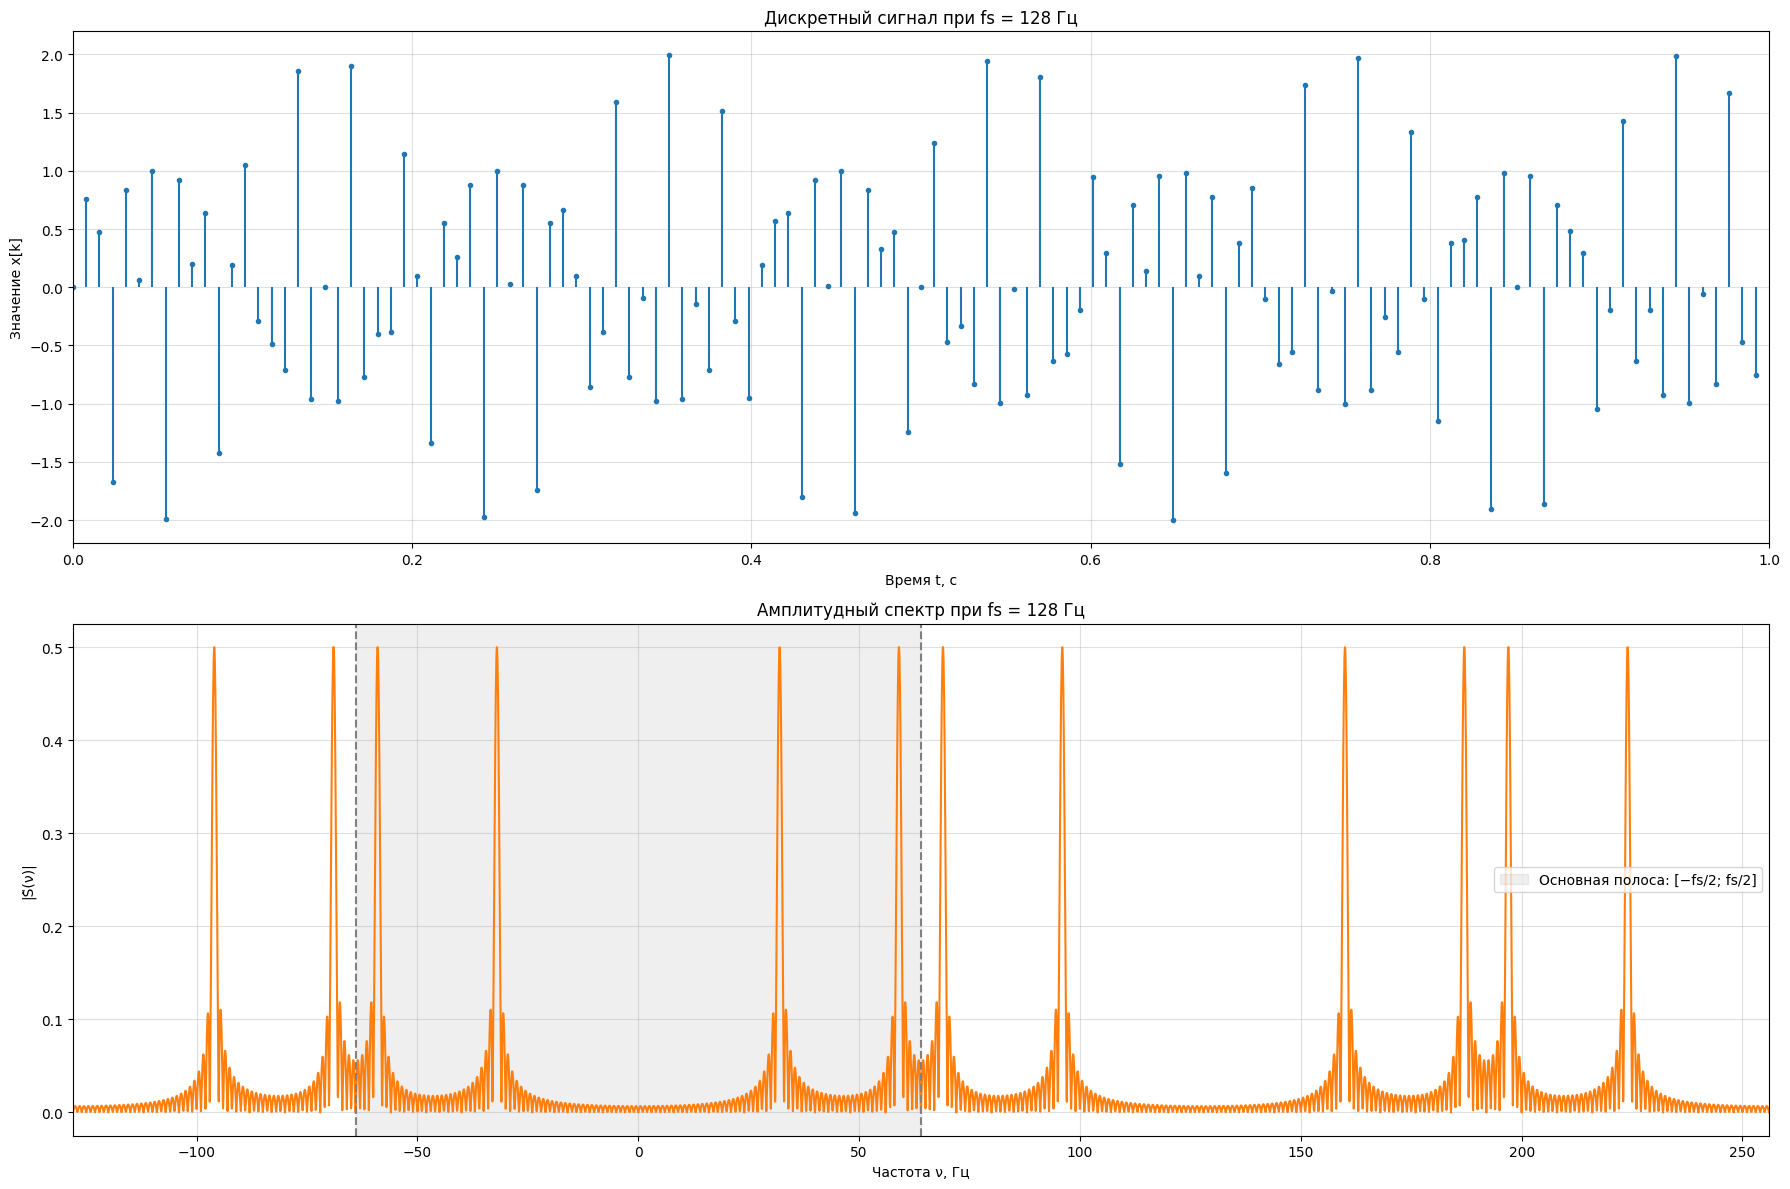

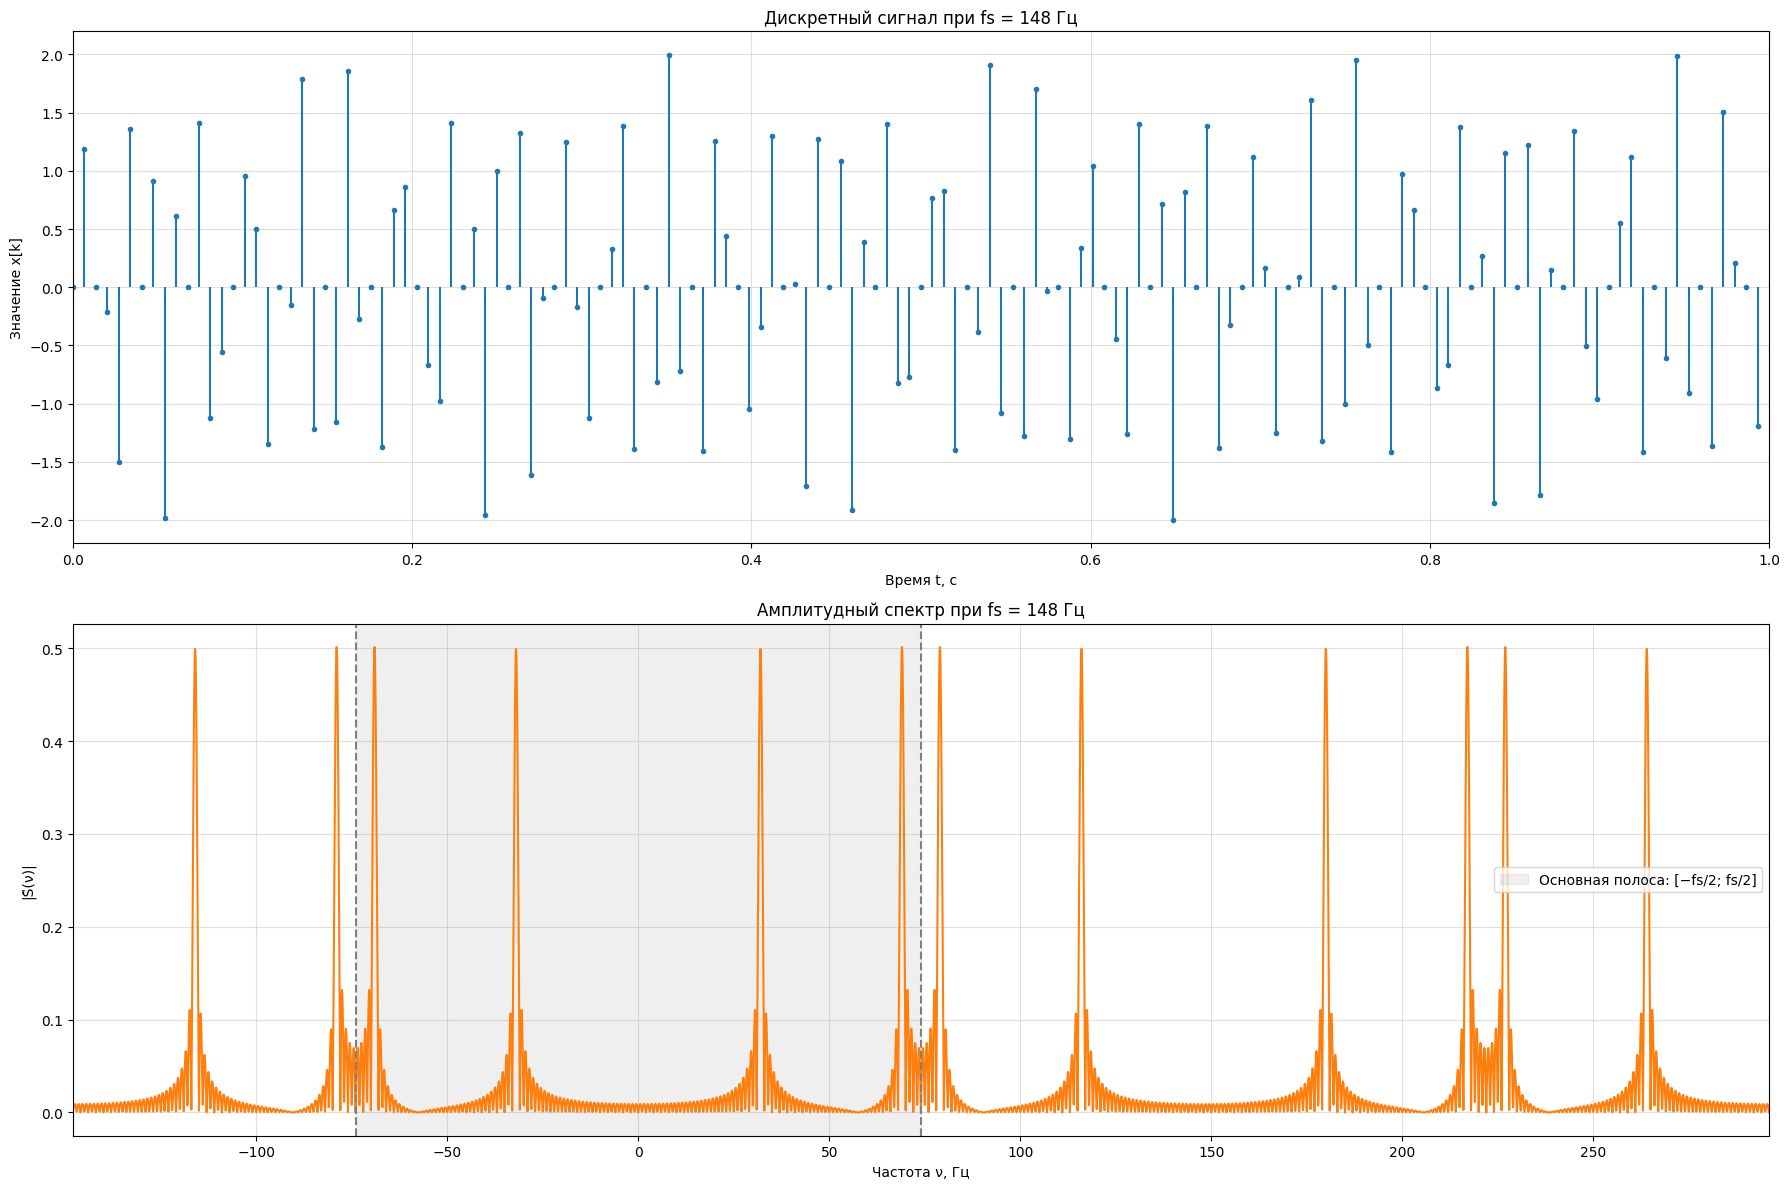

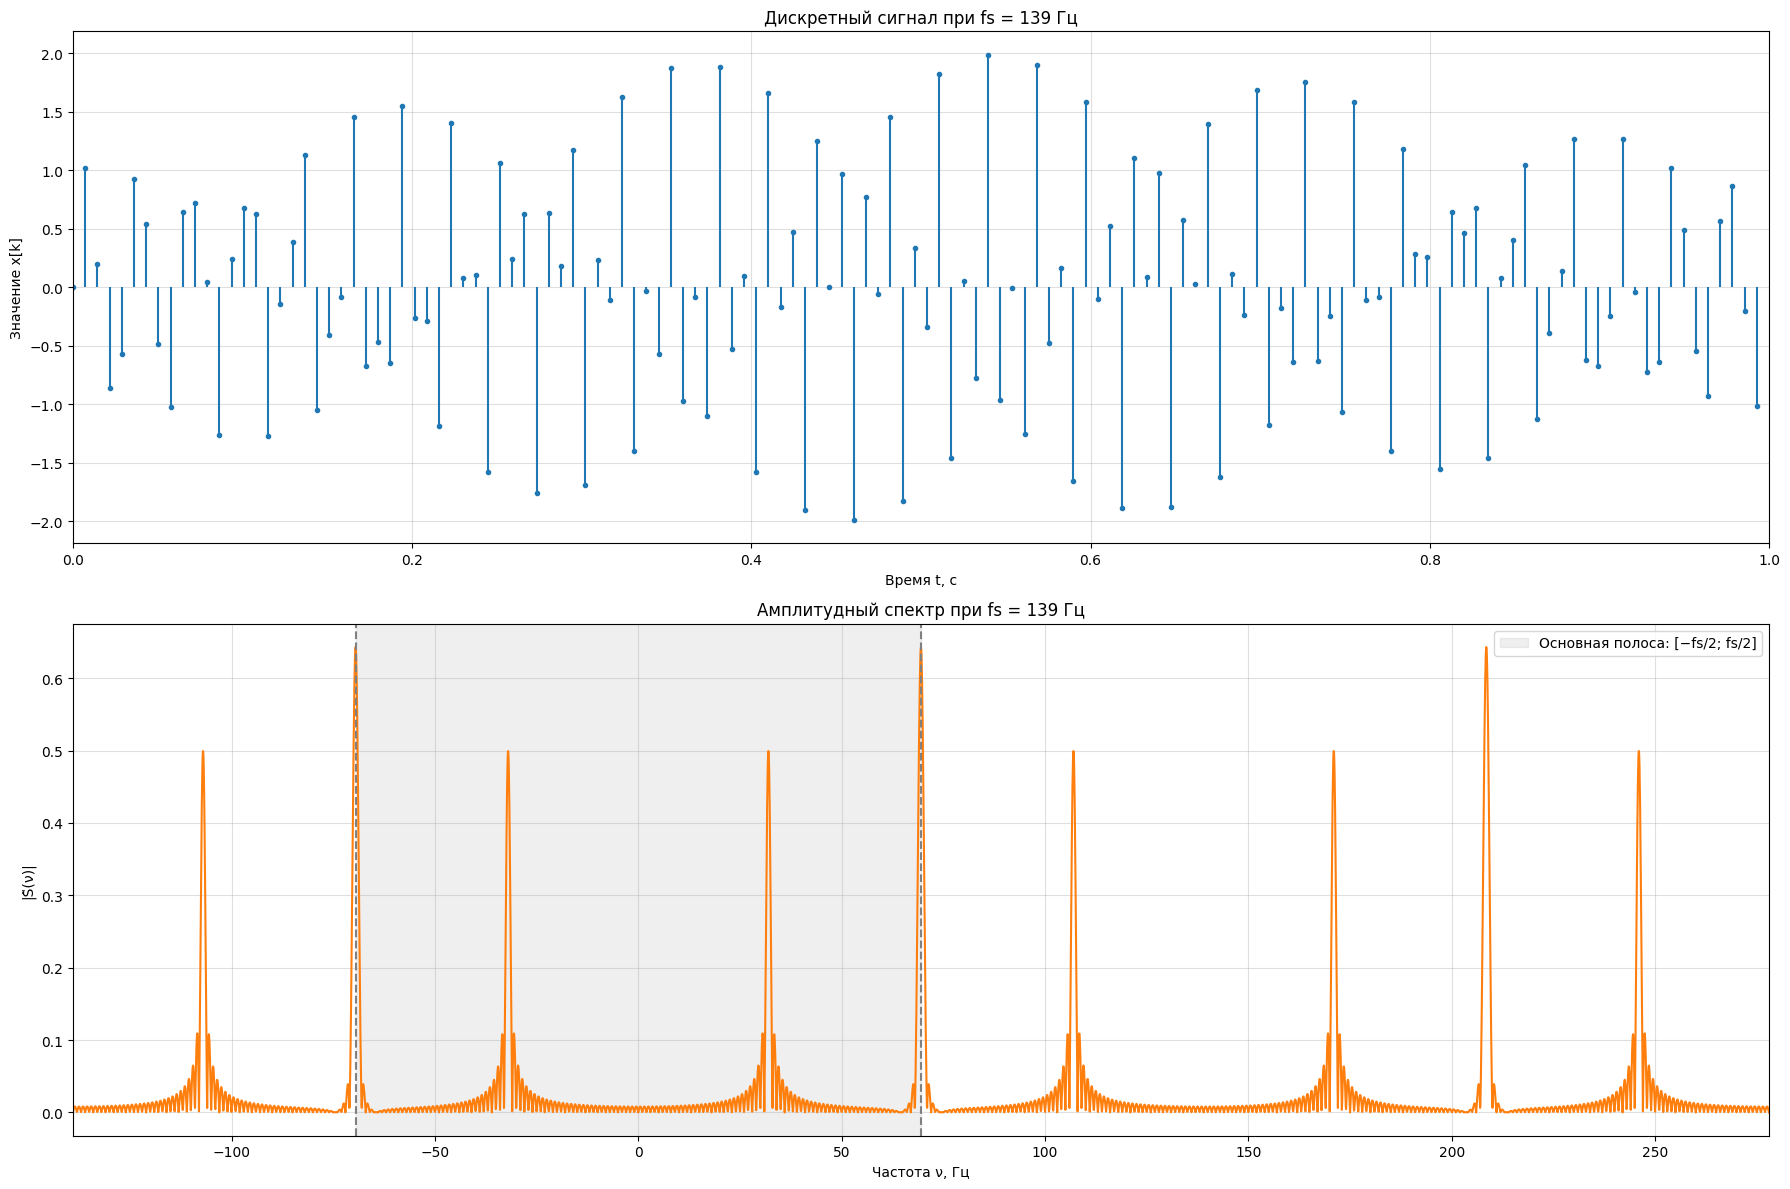

In [15]:
import matplotlib.pyplot as plt


def discrete_spectrum(frequencies, t_samples, x_samples, dt):
    """Вычисляет спектр непосредственно по формуле из методички."""
    exponents = np.exp(
        -2j * np.pi * frequencies[:, None] * t_samples[None, :]
    )

    return dt * (exponents @ x_samples)


for fs, data in sampled_signals.items():
    dt = data["dt"]
    t_samples = data["t"]
    x_samples = data["x"]

    # Частотная сетка от -fs до 2fs, включая обе границы
    frequencies = np.linspace(-fs, 2 * fs, 6001)

    spectrum = discrete_spectrum(
        frequencies, t_samples, x_samples, dt
    )
    amplitude = np.abs(spectrum)

    fig, axes = plt.subplots(2, 1, figsize=(18, 12))

    # Дискретный сигнал: отдельные отсчёты
    axes[0].stem(
        t_samples,
        x_samples,
        linefmt="C0-",
        markerfmt="C0.",
        basefmt=" "
    )
    axes[0].set_title(f"Дискретный сигнал при fs = {fs} Гц")
    axes[0].set_xlabel("Время t, с")
    axes[0].set_ylabel("Значение x[k]")
    axes[0].set_xlim(0, T)
    axes[0].grid(True, alpha=0.4)

    # Амплитудный спектр
    axes[1].plot(frequencies, amplitude, color="C1")

    # Основная полоса частот и её границы
    axes[1].axvspan(
        -fs / 2, fs / 2,
        color="gray", alpha=0.12,
        label="Основная полоса: [−fs/2; fs/2]"
    )
    axes[1].axvline(-fs / 2, color="gray", linestyle="--")
    axes[1].axvline(fs / 2, color="gray", linestyle="--")

    axes[1].set_title(f"Амплитудный спектр при fs = {fs} Гц")
    axes[1].set_xlabel("Частота ν, Гц")
    axes[1].set_ylabel("|S̃(ν)|")
    axes[1].set_xlim(-fs, 2 * fs)
    axes[1].grid(True, alpha=0.4)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### Задание 4

Проиллюстрировать на примере сигнала $x(t)$ эффект наложения
частот. Привести сигнал $y(t)$, который при некоторой частоте
дискретизации имеет те же отсчёты, что и $x(t)$.

Выполнить восстановление сигнала по отсчётам с помощью
ряда Котельникова.

### Решение

Выберем частоту дискретизации $f_s=128$ Гц.
Частота Найквиста равна:

$$
\frac{f_s}{2}=64\text{ Гц}.
$$

Гармоника с частотой 69 Гц превышает эту границу.
В моменты дискретизации $t_k=k/128$ имеем:

$$
\sin\left(2\pi\frac{69k}{128}\right)
=\sin\left(2\pi k-2\pi\frac{59k}{128}\right)
=-\sin\left(2\pi\frac{59k}{128}\right).
$$

Следовательно, сигнал

$$
y(t)=
\begin{cases}
\sin(64\pi t)-\sin(118\pi t), & t\in[0;1],\\
0, & t\notin[0;1]
\end{cases}
$$

совпадает с исходным сигналом во всех точках дискретизации:

$$
\boxed{x(k/128)=y(k/128).}
$$

При этом между точками дискретизации значения сигналов
в общем случае различаются.

Восстановим сигнал по сохранённым отсчётам:

$$
x_{\mathrm{rec}}(t)
=\sum_{k=0}^{N-1}x_k
\operatorname{sinc}\left(f_s(t-t_k)\right),
$$

где используется нормированная функция:

$$
\operatorname{sinc}(u)=
\begin{cases}
\dfrac{\sin(\pi u)}{\pi u}, & u\ne0,\\
1, & u=0.
\end{cases}
$$

Именно такое определение реализовано в `np.sinc`.

Максимальное различие отсчётов: 7.083222897108499e-14
Отсчёты совпадают с учётом погрешности вычислений: True


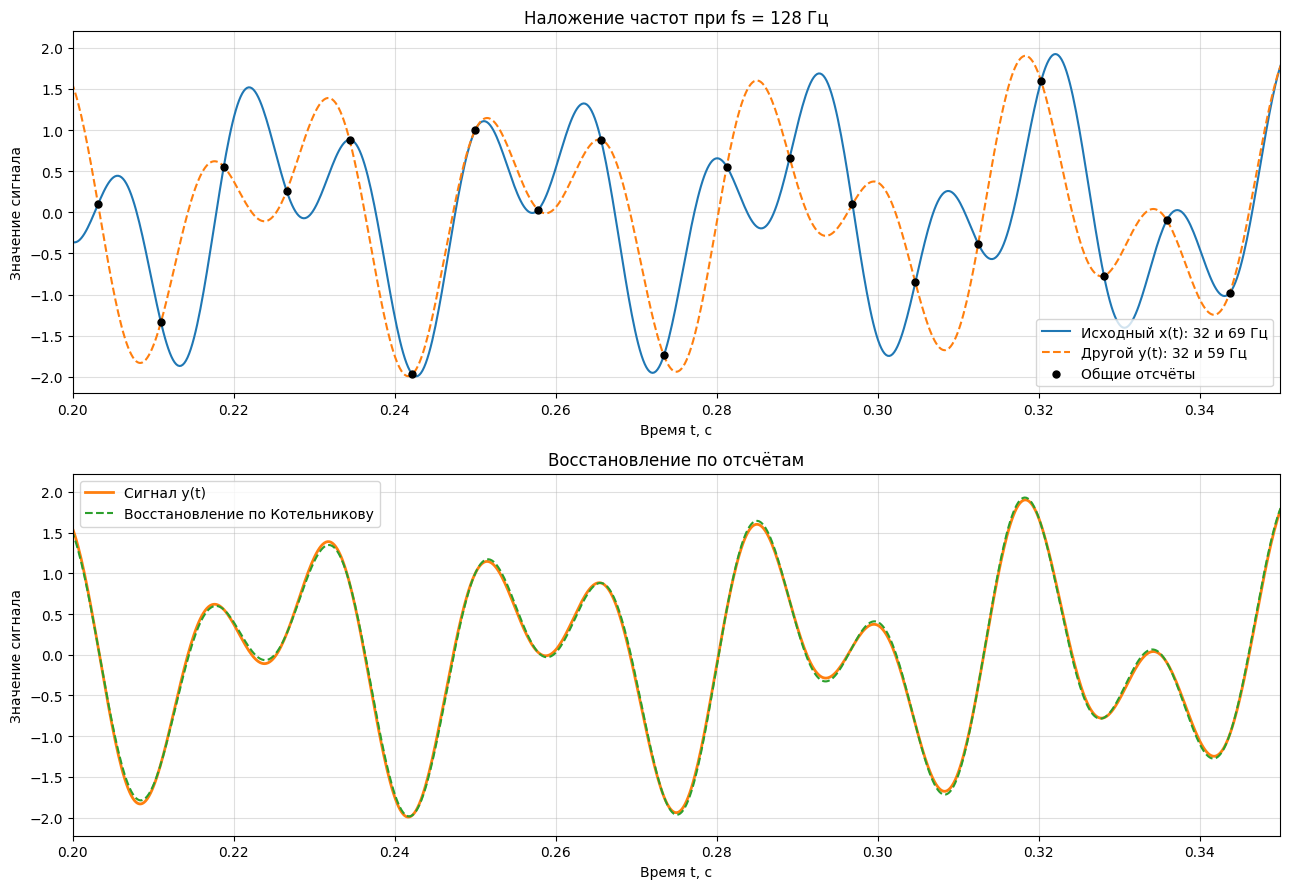

In [16]:
# Используем отсчёты, полученные в задании 2
fs = 128
t_samples = sampled_signals[fs]["t"]
x_samples = sampled_signals[fs]["x"]

# Частота, в которую переходит гармоника 69 Гц
alias_frequency = fs - nu2  # 59 Гц


def alias_signal(t):
    """Сигнал с теми же отсчётами при fs = 128 Гц."""
    values = (
        np.sin(2 * np.pi * nu1 * t)
        - np.sin(2 * np.pi * alias_frequency * t)
    )
    return np.where((t >= 0) & (t <= T), values, 0.0)


# Проверяем совпадение отсчётов двух сигналов
y_samples = alias_signal(t_samples)

print(
    "Максимальное различие отсчётов:",
    np.max(np.abs(x_samples - y_samples))
)
print(
    "Отсчёты совпадают с учётом погрешности вычислений:",
    np.allclose(x_samples, y_samples, rtol=0, atol=1e-12)
)

# Плотная сетка для изображения непрерывных кривых
t_dense = np.linspace(0, T, 5000)

x_dense = signal(t_dense)
y_dense = alias_signal(t_dense)

# Восстановление по конечной сумме Котельникова
sinc_matrix = np.sinc(
    fs * (t_dense[:, None] - t_samples[None, :])
)
x_restored = sinc_matrix @ x_samples

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Показываем небольшой участок, чтобы различать колебания
left, right = 0.2, 0.35
visible_samples = (
    (t_samples >= left) & (t_samples <= right)
)

# Разные непрерывные сигналы с одинаковыми отсчётами
axes[0].plot(
    t_dense, x_dense,
    label="Исходный x(t): 32 и 69 Гц",
    linewidth=1.5
)
axes[0].plot(
    t_dense, y_dense,
    "--", label="Другой y(t): 32 и 59 Гц",
    linewidth=1.5
)
axes[0].scatter(
    t_samples[visible_samples],
    x_samples[visible_samples],
    color="black", s=25, zorder=3,
    label="Общие отсчёты"
)
axes[0].set_title("Наложение частот при fs = 128 Гц")
axes[0].set_ylabel("Значение сигнала")
axes[0].legend()

# Сравнение восстановленного сигнала с y(t)
axes[1].plot(
    t_dense, y_dense,
    color="C1", label="Сигнал y(t)",
    linewidth=2
)
axes[1].plot(
    t_dense, x_restored,
    "--", color="C2",
    label="Восстановление по Котельникову",
    linewidth=1.5
)
axes[1].set_title("Восстановление по отсчётам")
axes[1].set_ylabel("Значение сигнала")
axes[1].legend()

for ax in axes:
    ax.set_xlim(left, right)
    ax.set_xlabel("Время t, с")
    ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

### Задание 5

Загрузить тестовое изображение своего варианта.

1. Уменьшить частоту дискретизации изображения в 2, 3 и 4 раза
   прореживанием его строк и столбцов.
2. Восстановить изображение до исходного размера с помощью
   ряда Котельникова.
3. Выполнить уменьшение и восстановление изображения функцией
   `skimage.transform.resize` с параметром `order=2`.
4. Сравнить полученные результаты.

Для варианта 6 используется изображение `var6.png`.

### Решение

Изображение в оттенках серого представляется матрицей $f[m,n]$.
Каждый элемент матрицы задаёт яркость одного пикселя.

При прореживании в $k$ раз сохраняем каждую $k$-ю строку
и каждый $k$-й столбец:

$$
f_k[p,q]=f[kp,kq].
$$

Число пикселей при этом уменьшается приблизительно в $k^2$ раз.

Восстановление изображения выполняется по двумерной формуле:

$$
F[m,n]=
\sum_{p=0}^{M_k-1}
\sum_{q=0}^{N_k-1}
f_k[p,q]\,
\operatorname{sinc}\left(\frac{m}{k}-p\right)
\operatorname{sinc}\left(\frac{n}{k}-q\right),
$$

где $M_k$ и $N_k$ — размеры прореженного изображения.

В матричной форме:

$$
F=A f_k B^{\mathsf T},
$$

где

$$
A_{m,p}=\operatorname{sinc}\left(\frac{m}{k}-p\right),
\qquad
B_{n,q}=\operatorname{sinc}\left(\frac{n}{k}-q\right).
$$

Для сравнения используем квадратичную интерполяцию
`resize(..., order=2)`. При уменьшении включаем сглаживание
`anti_aliasing=True`, чтобы ослабить наложение пространственных
частот.

Исходный размер: 320 × 557 пикселей
k = 2: 320 × 557 → 160 × 279 → 320 × 557


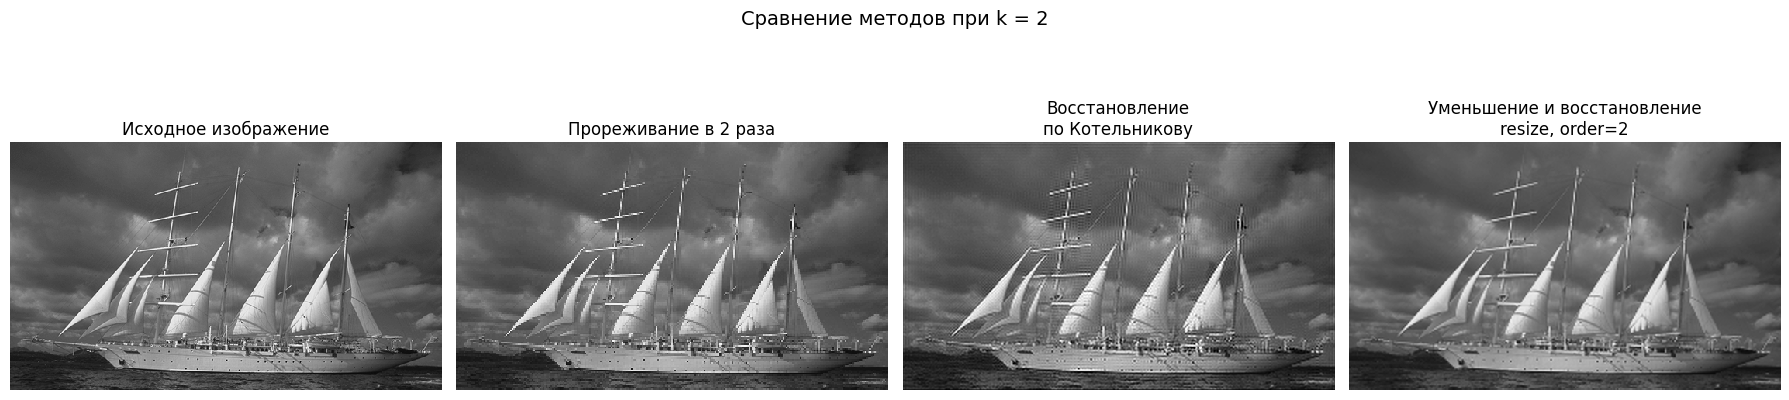

k = 3: 320 × 557 → 107 × 186 → 320 × 557


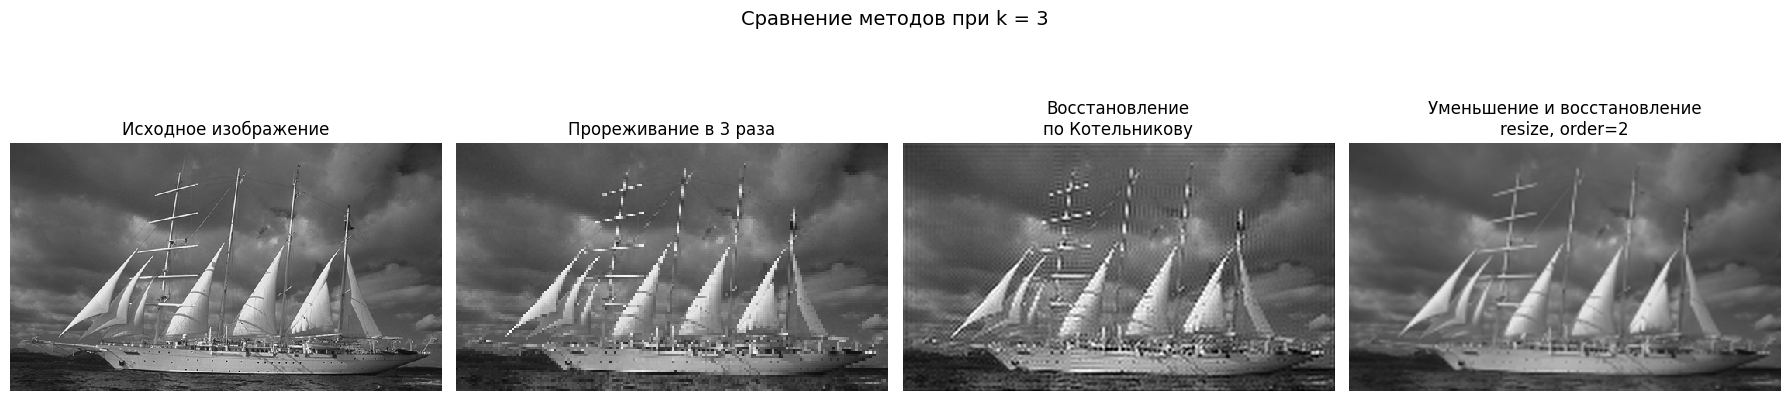

k = 4: 320 × 557 → 80 × 140 → 320 × 557


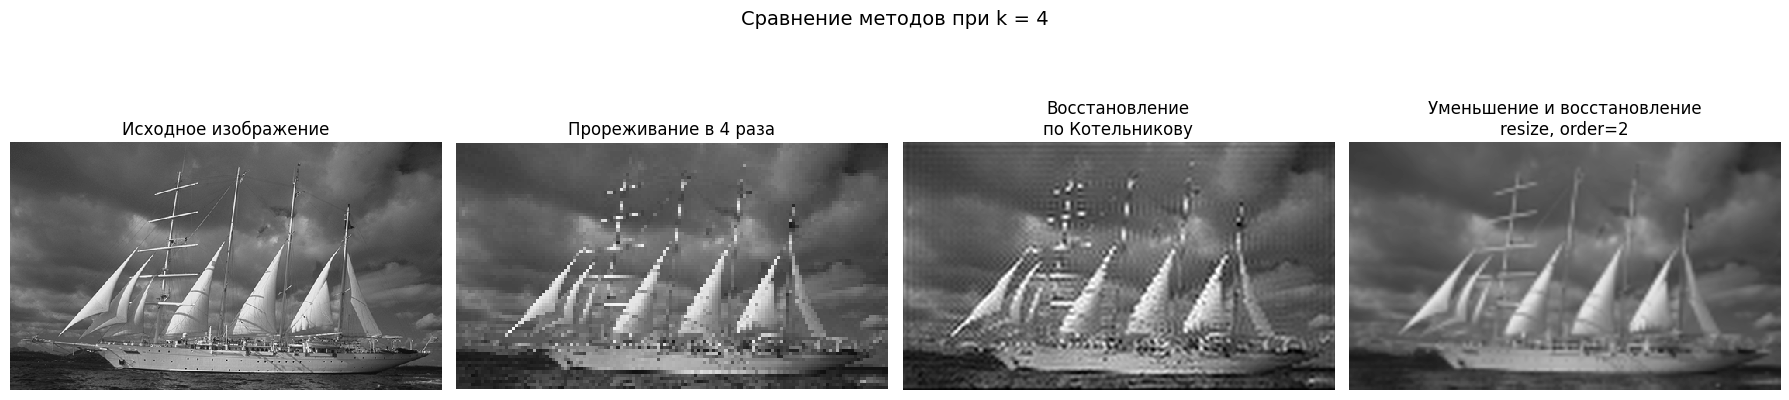

In [17]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from skimage.io import imread
from skimage.util import img_as_float
from skimage.transform import resize


# Загружаем изображение своего варианта
image_path = Path("test_images") / "var6.png"

fd = img_as_float(imread(image_path, as_gray=True))
M, N = fd.shape

print(f"Исходный размер: {M} × {N} пикселей")


def restore_image_sinc(reduced, original_shape, k):
    """Восстанавливает изображение по двумерной формуле Котельникова."""
    M, N = original_shape
    Mk, Nk = reduced.shape

    # Координаты пикселей исходного изображения
    rows = np.arange(M)
    columns = np.arange(N)

    # Номера отсчётов прореженного изображения
    reduced_rows = np.arange(Mk)
    reduced_columns = np.arange(Nk)

    # Матрицы sinc-интерполяции по строкам и столбцам
    A = np.sinc(
        rows[:, None] / k - reduced_rows[None, :]
    )
    B = np.sinc(
        columns[:, None] / k - reduced_columns[None, :]
    )

    return A @ reduced @ B.T


# Сохраняем результаты для дальнейшего анализа
image_results = {}

for k in [2, 3, 4]:
    # 1. Прореживание без предварительного сглаживания
    reduced = fd[::k, ::k]

    # 2. Восстановление по Котельникову
    restored_sinc = restore_image_sinc(reduced, fd.shape, k)

    # 3. Уменьшение функцией resize до того же размера
    reduced_resize = resize(
        fd,
        output_shape=reduced.shape,
        order=2,
        anti_aliasing=True,
        preserve_range=True
    )

    # 4. Восстановление функцией resize
    restored_resize = resize(
        reduced_resize,
        output_shape=fd.shape,
        order=2,
        anti_aliasing=False,
        preserve_range=True
    )

    image_results[k] = {
        "reduced": reduced,
        "restored_sinc": restored_sinc,
        "reduced_resize": reduced_resize,
        "restored_resize": restored_resize,
    }

    print(
        f"k = {k}: {M} × {N} → "
        f"{reduced.shape[0]} × {reduced.shape[1]} → {M} × {N}"
    )

    # Сравнение результатов
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    images = [
        fd,
        reduced,
        restored_sinc,
        restored_resize
    ]

    titles = [
        "Исходное изображение",
        f"Прореживание в {k} раза",
        "Восстановление\nпо Котельникову",
        "Уменьшение и восстановление\nresize, order=2"
    ]

    for ax, image, title in zip(axes, images, titles):
        ax.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(f"Сравнение методов при k = {k}", fontsize=14)
    plt.tight_layout()
    plt.show()

## Часть 2. Исследование эффектов квантования

### Задание 1

Синтезировать случайный дискретный сигнал $x(k)$, состоящий
из нескольких сотен отсчётов с одинаковым равномерным
распределением. Построить по отсчётам его график.

### Решение

Сформируем сигнал из $n=500$ независимых отсчётов,
равномерно распределённых на интервале $[0;1)$:

$$
x(k)\sim U[0;1),\qquad k=0,1,\ldots,499.
$$

Плотность распределения каждого отсчёта:

$$
p(x)=
\begin{cases}
1, & 0\le x<1,\\
0, & \text{иначе}.
\end{cases}
$$

Равномерное распределение означает, что вероятность попадания
значения в интервал зависит только от его длины:
интервалы одинаковой длины внутри $[0;1)$ равновероятны.

На графике изображаем отдельные отсчёты, не соединяя
соседние точки линиями.

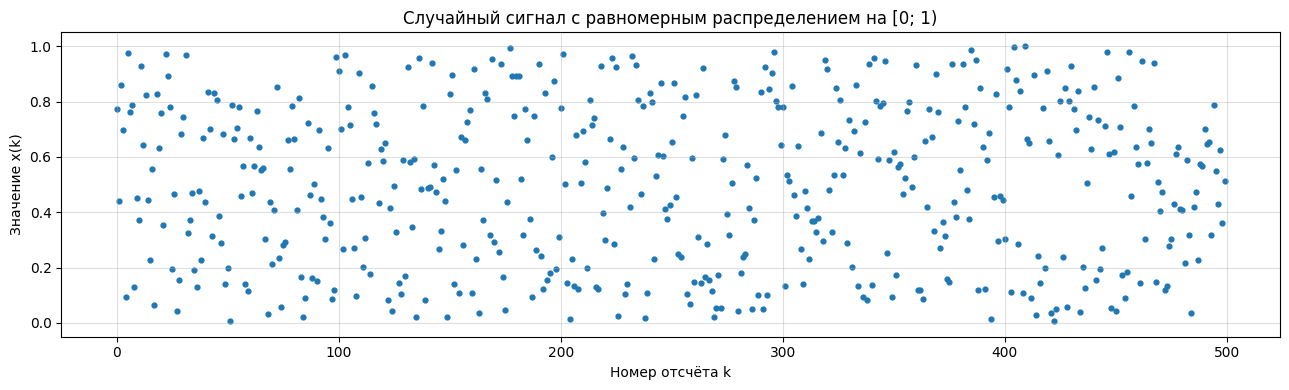

Количество отсчётов: 500
Минимальное значение: 0.005430
Максимальное значение: 0.999105


In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Фиксируем начальное состояние генератора для повторяемости
rng = np.random.default_rng(42)

# Параметры сигнала
n_samples = 500
xmin = 0.0
xmax = 1.0

# Номера отсчётов
sample_indices = np.arange(n_samples)

# Независимые отсчёты с равномерным распределением
x_uniform = rng.uniform(
    low=xmin,
    high=xmax,
    size=n_samples
)

# График дискретного сигнала
plt.figure(figsize=(13, 4))

plt.scatter(
    sample_indices,
    x_uniform,
    s=12,
    color="C0"
)

plt.title("Случайный сигнал с равномерным распределением на [0; 1)")
plt.xlabel("Номер отсчёта k")
plt.ylabel("Значение x(k)")
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Количество отсчётов: {len(x_uniform)}")
print(f"Минимальное значение: {x_uniform.min():.6f}")
print(f"Максимальное значение: {x_uniform.max():.6f}")

### Задание 2

Провести равномерное квантование отсчётов сигнала $x(k),
используя от 1 до 8 бит на отсчёт.

Построить ступенчатые графики сигнала после квантования
с помощью функции `matplotlib.pyplot.stairs`.

### Решение

Используем полученный ранее сигнал из 500 отсчётов
на интервале $[0;1)$.

При выделении $b$ бит на отсчёт количество уровней квантования:

$$
L=2^b.
$$

Шаг равномерного квантования:

$$
q=\frac{x_{\max}-x_{\min}}{L}=\frac{1}{2^b}.
$$

По формуле методички квантованное значение определяется как:

$$
\widehat{x}(k)=
\left(
\left\lfloor\frac{x(k)}{q}\right\rfloor+\frac12
\right)q.
$$

Операция $\lfloor x(k)/q\rfloor$ определяет номер интервала,
в который попал отсчёт. Затем отсчёт заменяется серединой
этого интервала.

Например, при $b=2$ получаем четыре уровня:

$$
L=4,\qquad q=0{,}25,
$$

$$
d_0=0{,}125,\quad d_1=0{,}375,\quad
d_2=0{,}625,\quad d_3=0{,}875.
$$

Значение $x(k)=0{,}68$ попадает в интервал $[0{,}5;0{,}75)$
и заменяется его серединой:

$$
\widehat{x}(k)=0{,}625.
$$

Биты | Уровни | Шаг квантования
----------------------------------
   1 |      2 | 0.50000000
   2 |      4 | 0.25000000
   3 |      8 | 0.12500000
   4 |     16 | 0.06250000
   5 |     32 | 0.03125000
   6 |     64 | 0.01562500
   7 |    128 | 0.00781250
   8 |    256 | 0.00390625


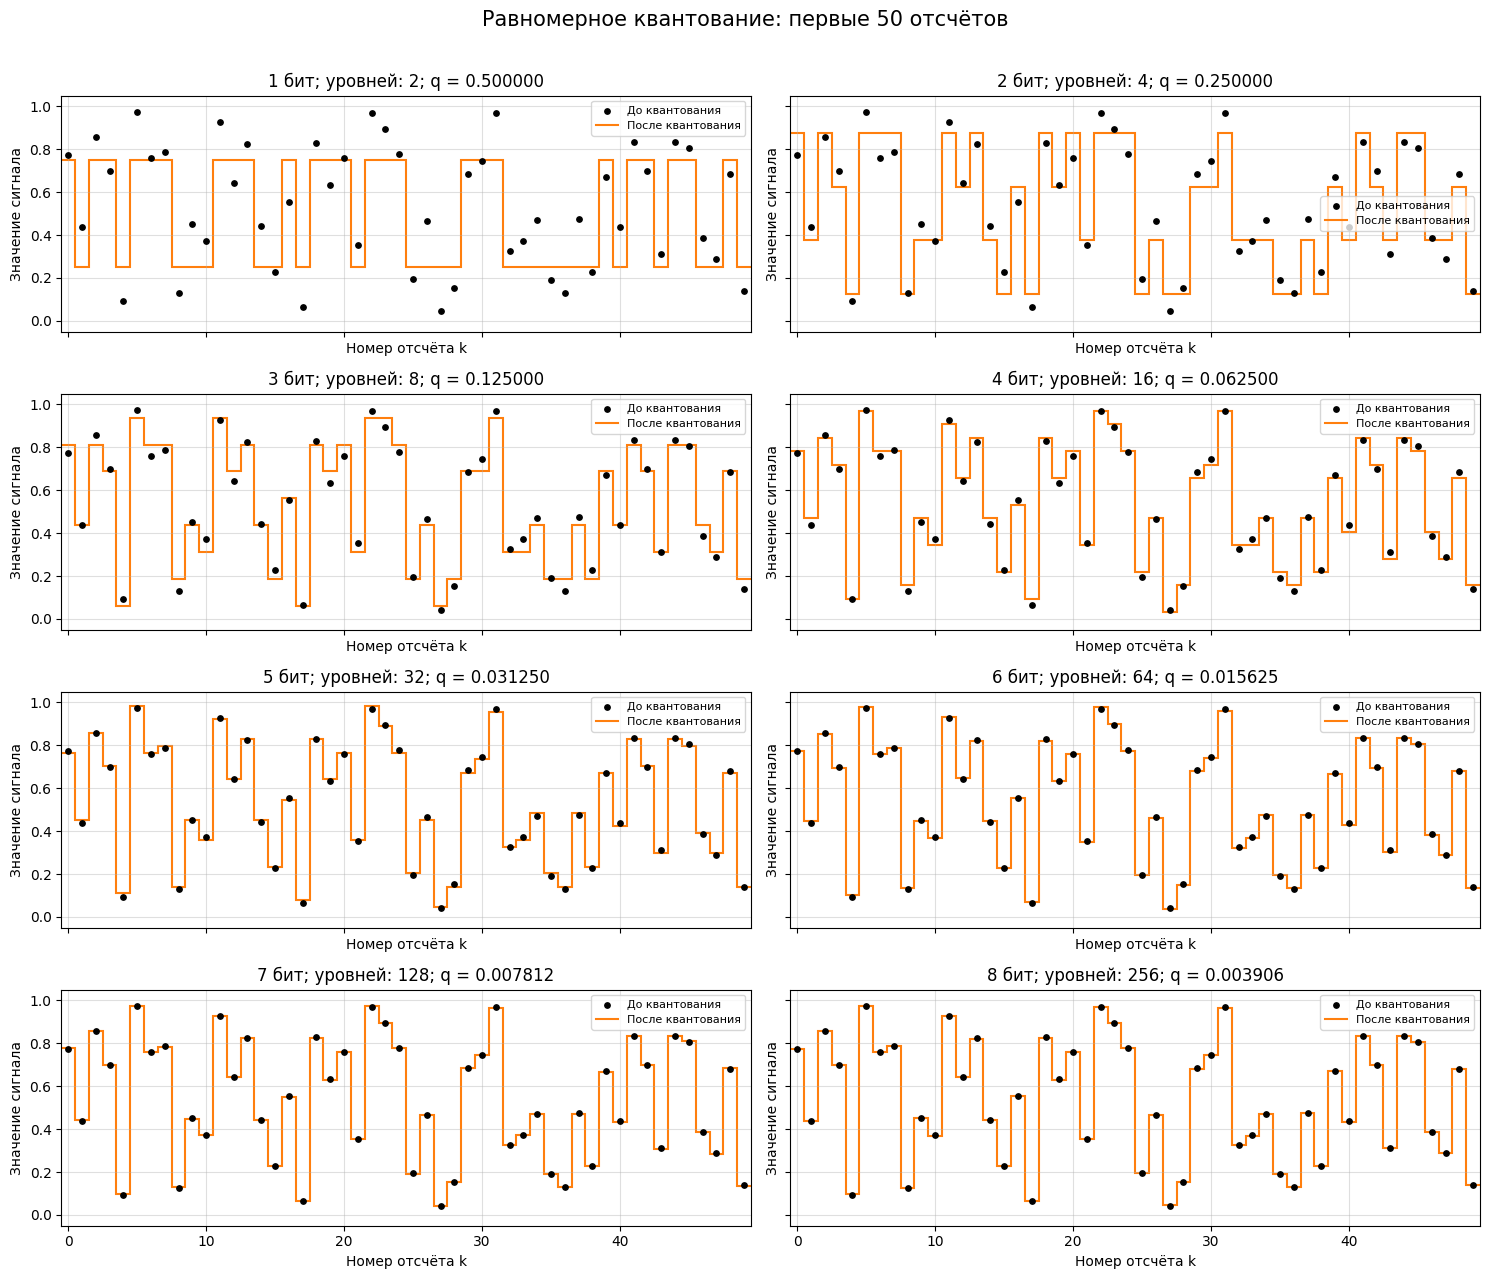

In [19]:
# Используем x_uniform, xmin, xmax из предыдущего задания

# Сохраняем результаты для последующего расчёта ошибки и SNR
quantized_uniform = {}

fig, axes = plt.subplots(
    4, 2,
    figsize=(15, 13),
    sharex=True,
    sharey=True
)

# Показываем первые 50 отсчётов, чтобы ступени были различимы.
# Квантование выполняем для всех 500 отсчётов.
n_display = 50

# Границы ступеней: ступень с номером k расположена вокруг точки k
edges = np.arange(n_display + 1) - 0.5

print("Биты | Уровни | Шаг квантования")
print("-" * 34)

for bits, ax in zip(range(1, 9), axes.flat):
    levels = 2 ** bits
    q = (xmax - xmin) / levels

    # Номер интервала для каждого отсчёта
    indices = np.floor((x_uniform - xmin) / q).astype(int)

    # Ограничиваем номера допустимым диапазоном
    indices = np.clip(indices, 0, levels - 1)

    # Заменяем значения серединами интервалов
    x_quantized = xmin + (indices + 0.5) * q

    quantized_uniform[bits] = {
        "levels": levels,
        "q": q,
        "x": x_quantized,
    }

    # Исходные отсчёты — отдельные точки
    ax.scatter(
        sample_indices[:n_display],
        x_uniform[:n_display],
        color="black",
        s=15,
        zorder=3,
        label="До квантования"
    )

    # Квантованный сигнал — ступени
    ax.stairs(
        x_quantized[:n_display],
        edges,
        baseline=None,
        color="C1",
        linewidth=1.5,
        label="После квантования"
    )

    ax.set_title(
        f"{bits} бит; уровней: {levels}; q = {q:.6f}"
    )
    ax.set_xlabel("Номер отсчёта k")
    ax.set_ylabel("Значение сигнала")
    ax.set_xlim(-0.5, n_display - 0.5)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.4)
    ax.legend(fontsize=8)

    print(f"{bits:4d} | {levels:6d} | {q:.8f}")

fig.suptitle(
    "Равномерное квантование: первые 50 отсчётов",
    fontsize=15
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

увеличение числа битов уменьшает  отклонение квантованных значений от исходных.

### Задание 3

По отсчётам исходного и квантованных сигналов найти выборочные
значения ошибки квантования. Сравнить результаты с теоретической
оценкой.

Построить на одном графике зависимости теоретической оценки
и выборочного значения ошибки от количества битов на отсчёт.

### Решение

Для каждого количества битов $b=1,\ldots,8$ вычислим средний
квадрат ошибки квантования:

$$
\widehat{\varepsilon^2}
=\frac{1}{n}\sum_{k=0}^{n-1}
\left(x(k)-\widehat{x}(k)\right)^2,
$$

где $n=500$ — количество отсчётов.

Для равномерного распределения на $[0;1)$ и равномерного
квантования с заменой значений серединами интервалов
теоретический средний квадрат ошибки равен:

$$
\overline{\varepsilon^2}=\frac{q^2}{12}.
$$

Поскольку $q=2^{-b}$, получаем:

$$
\boxed{
\overline{\varepsilon^2}
=\frac{1}{12\cdot 4^b}.
}
$$

Таким образом, при добавлении одного бита теоретический
средний квадрат ошибки уменьшается в четыре раза.

Для сравнения вычислим также относительное отклонение
выборочного результата от теоретического:

$$
\delta=
\frac{\left|
\widehat{\varepsilon^2}-\overline{\varepsilon^2}
\right|}
{\overline{\varepsilon^2}}
\cdot100\%.
$$

Биты |  Выборочная ошибка |   Теоретическая |  Отклонение, %
----------------------------------------------------------------
   1 |     1.99387652e-02 |  2.08333333e-02 |           4.29
   2 |     4.82867630e-03 |  5.20833333e-03 |           7.29
   3 |     1.24360575e-03 |  1.30208333e-03 |           4.49
   4 |     3.14767221e-04 |  3.25520833e-04 |           3.30
   5 |     8.04890148e-05 |  8.13802083e-05 |           1.10
   6 |     1.99904923e-05 |  2.03450521e-05 |           1.74
   7 |     5.08415590e-06 |  5.08626302e-06 |           0.04
   8 |     1.20315541e-06 |  1.27156576e-06 |           5.38


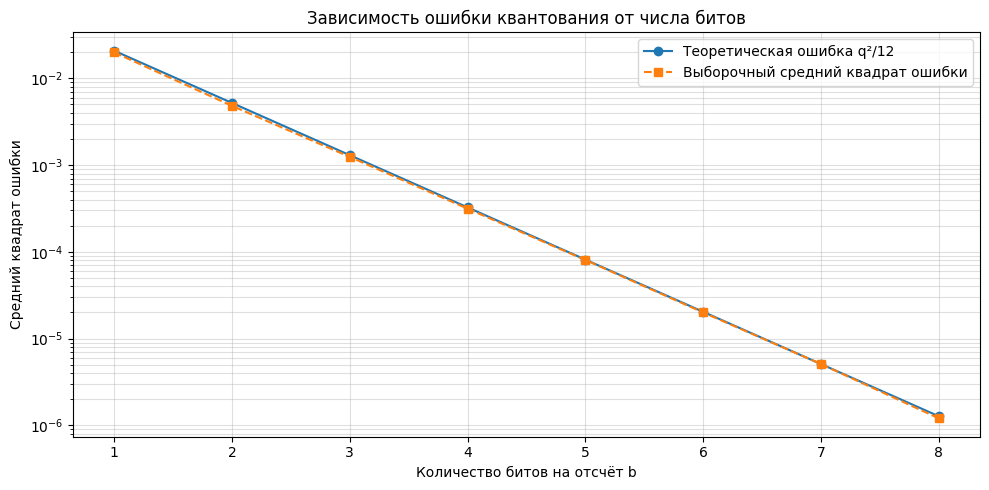

In [20]:
bits_values = np.arange(1, 9)

empirical_errors = []
theoretical_errors = []

print(
    f"{'Биты':>4} | {'Выборочная ошибка':>18} | "
    f"{'Теоретическая':>15} | {'Отклонение, %':>14}"
)
print("-" * 64)

for bits in bits_values:
    data = quantized_uniform[bits]

    x_quantized = data["x"]
    q = data["q"]

    # Ошибка каждого отсчёта
    errors = x_uniform - x_quantized

    # Выборочный средний квадрат ошибки по всем 500 отсчётам
    empirical_mse = np.mean(errors ** 2)

    # Теоретический средний квадрат ошибки
    theoretical_mse = q ** 2 / 12

    relative_difference = (
        abs(empirical_mse - theoretical_mse)
        / theoretical_mse
        * 100
    )

    empirical_errors.append(empirical_mse)
    theoretical_errors.append(theoretical_mse)

    print(
        f"{bits:4d} | {empirical_mse:18.8e} | "
        f"{theoretical_mse:15.8e} | {relative_difference:14.2f}"
    )

empirical_errors = np.array(empirical_errors)
theoretical_errors = np.array(theoretical_errors)

# Обе зависимости на одном графике
plt.figure(figsize=(10, 5))

plt.semilogy(
    bits_values,
    theoretical_errors,
    "o-",
    label="Теоретическая ошибка q²/12"
)

plt.semilogy(
    bits_values,
    empirical_errors,
    "s--",
    label="Выборочный средний квадрат ошибки"
)

plt.title("Зависимость ошибки квантования от числа битов")
plt.xlabel("Количество битов на отсчёт b")
plt.ylabel("Средний квадрат ошибки")
plt.xticks(bits_values)
plt.grid(True, which="both", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

### Задание 4. Отношение сигнал/шум

Вычислить отношение сигнал/шум для равномерного квантования
с разрядностью от 1 до 8 бит. Построить график зависимости
отношения сигнал/шум от числа бит.

Среднеквадратическое значение исходного сигнала:

$$
x_{\mathrm{RMS}} =
\sqrt{\frac{1}{n}\sum_{k=0}^{n-1}x^2(k)}.
$$

Среднеквадратическое значение ошибки квантования:

$$
e_{\mathrm{RMS}} =
\sqrt{\frac{1}{n}\sum_{k=0}^{n-1}
\left(x(k)-\hat{x}(k)\right)^2}.
$$

Отношение сигнал/шум в децибелах:

$$
\mathrm{SNR} =
20\log_{10}\frac{x_{\mathrm{RMS}}}{e_{\mathrm{RMS}}}.
$$

Эквивалентная запись через средние квадраты:

$$
\mathrm{SNR} =
10\log_{10}
\frac{\frac{1}{n}\sum_{k=0}^{n-1}x^2(k)}
{\frac{1}{n}\sum_{k=0}^{n-1}(x(k)-\hat{x}(k))^2}.
$$

Для равномерного распределения на [0, 1):

$$
\mathbb{E}[x^2]=\int_0^1 x^2\,dx=\frac{1}{3}.
$$

При шаге квантования $q=2^{-b}$ теоретический средний квадрат
ошибки равен $q^2/12$. Поэтому теоретическое отношение сигнал/шум:

$$
\mathrm{SNR}_{\mathrm{теор}}
=10\log_{10}\frac{1/3}{q^2/12}
=10\log_{10}(4^{b+1})
\approx 6{,}02(b+1)\ \text{дБ}.
$$

Таким образом, увеличение разрядности на один бит должно давать
прирост отношения сигнал/шум примерно на 6,02 дБ.

RMS исходного сигнала: 0.572515

Биты |   RMS ошибки |    SNR, дБ |  Теория, дБ
--------------------------------------------------
   1 |   0.14120469 |     12.159 |      12.041
   2 |   0.06948868 |     18.317 |      18.062
   3 |   0.03526479 |     24.209 |      24.082
   4 |   0.01774168 |     30.176 |      30.103
   5 |   0.00897157 |     36.098 |      36.124
   6 |   0.00447107 |     42.148 |      42.144
   7 |   0.00225481 |     48.094 |      48.165
   8 |   0.00109688 |     54.353 |      54.185


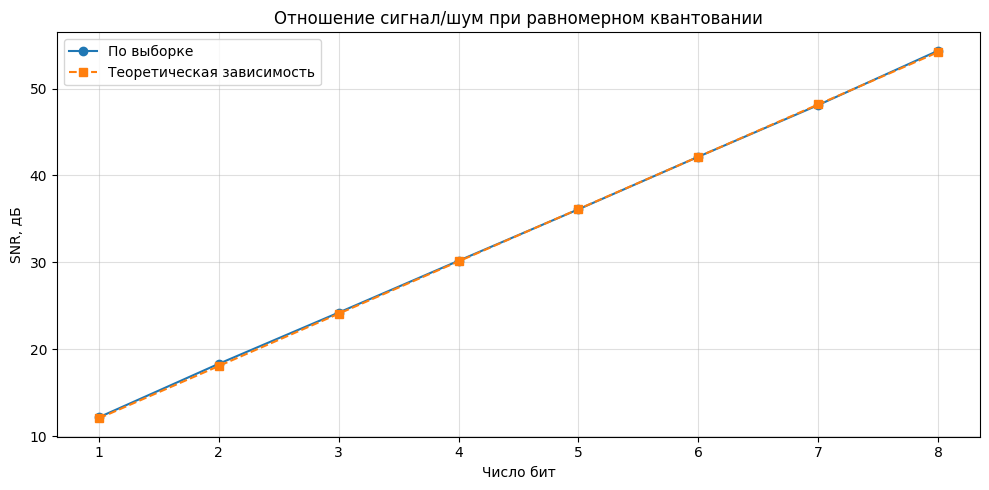

In [21]:
bits_values = np.arange(1, 9)

# RMS исходного сигнала одинаков для всех разрядностей.
signal_rms = np.sqrt(np.mean(x_uniform**2))

snr_uniform = []
snr_theoretical = []

print(f"RMS исходного сигнала: {signal_rms:.6f}\n")
print(
    f"{'Биты':>4} | {'RMS ошибки':>12} | "
    f"{'SNR, дБ':>10} | {'Теория, дБ':>11}"
)
print("-" * 50)

for bits in bits_values:
    data = quantized_uniform[bits]
    x_quantized = data["x"]
    q = data["q"]

    # Ошибка квантования и её среднеквадратическое значение.
    error = x_uniform - x_quantized
    error_rms = np.sqrt(np.mean(error**2))

    # Отношение сигнал/шум по выборке.
    snr = (
        20 * np.log10(signal_rms / error_rms)
        if error_rms > 0
        else np.inf
    )

    # Теория для равномерного распределения на [0, 1).
    snr_theory = 10 * np.log10((1 / 3) / (q**2 / 12))

    snr_uniform.append(snr)
    snr_theoretical.append(snr_theory)

    print(
        f"{bits:4d} | {error_rms:12.8f} | "
        f"{snr:10.3f} | {snr_theory:11.3f}"
    )

snr_uniform = np.array(snr_uniform)
snr_theoretical = np.array(snr_theoretical)

plt.figure(figsize=(10, 5))

plt.plot(
    bits_values,
    snr_uniform,
    "o-",
    label="По выборке",
)

plt.plot(
    bits_values,
    snr_theoretical,
    "s--",
    label="Теоретическая зависимость",
)

plt.title("Отношение сигнал/шум при равномерном квантовании")
plt.xlabel("Число бит")
plt.ylabel("SNR, дБ")
plt.xticks(bits_values)
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Задание 5. Генерация нормально распределённого сигнала

Сформировать последовательность случайных чисел с нормальным
распределением. Математическое ожидание равно номеру варианта,
а среднеквадратическое отклонение — номеру варианта плюс один.
Построить график полученного дискретного сигнала.

Для варианта 6:

$$
m=6,\qquad \sigma=7,\qquad \sigma^2=49.
$$

Таким образом, отсчёты сигнала имеют распределение:

$$
x(k)\sim\mathcal{N}(6,49),
$$

где второй параметр обозначает дисперсию.

Плотность распределения:

$$
p(x)=\frac{1}{7\sqrt{2\pi}}
\exp\left(-\frac{(x-6)^2}{98}\right).
$$

Сформируем 500 независимых отсчётов. Для проверки вычислим
выборочное среднее и выборочное стандартное отклонение:

$$
\bar{x}=\frac{1}{n}\sum_{k=0}^{n-1}x(k),
$$

$$
s=\sqrt{\frac{1}{n-1}\sum_{k=0}^{n-1}(x(k)-\bar{x})^2}.
$$

Эти оценки должны быть близки к 6 и 7 соответственно,
но могут отличаться из-за конечного объёма выборки.

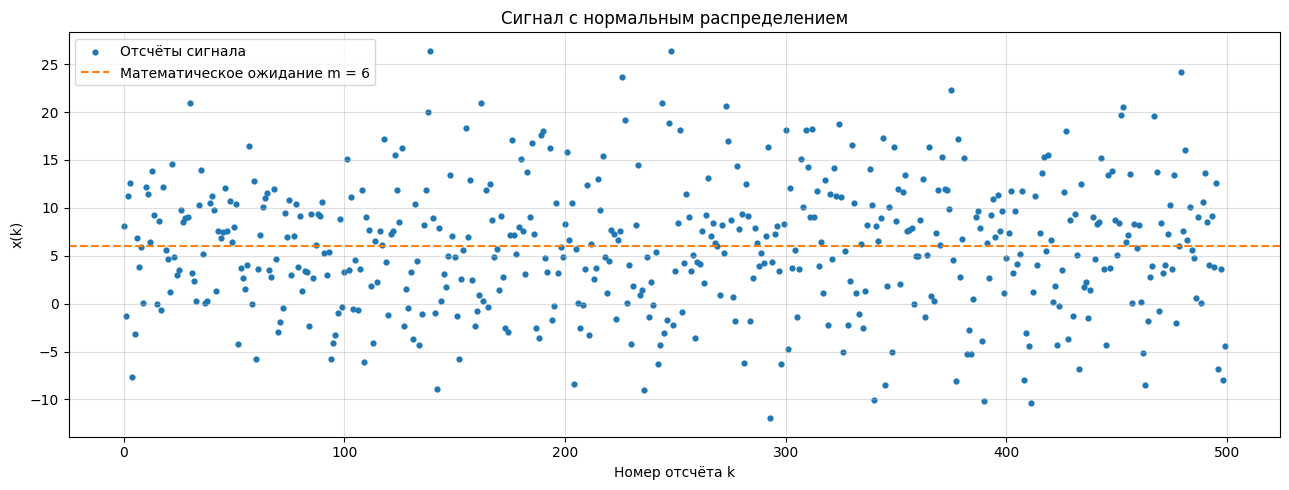

Количество отсчётов: 500
Заданное математическое ожидание: 6
Выборочное среднее: 5.9081
Заданное стандартное отклонение: 7
Выборочное стандартное отклонение: 6.7195


In [23]:
import numpy as np
import matplotlib.pyplot as plt

variant = 6
m = variant
sigma = variant + 1
n_samples = 500

rng_normal = np.random.default_rng(42)

# scale — стандартное отклонение, а не дисперсия.
x_normal = rng_normal.normal(
    loc=m,
    scale=sigma,
    size=n_samples,
)

sample_indices_normal = np.arange(n_samples)

plt.figure(figsize=(13, 5))

plt.scatter(
    sample_indices_normal,
    x_normal,
    s=12,
    label="Отсчёты сигнала",
)

plt.axhline(
    m,
    color="C1",
    linestyle="--",
    label=f"Математическое ожидание m = {m}",
)

plt.title("Сигнал с нормальным распределением")
plt.xlabel("Номер отсчёта k")
plt.ylabel("x(k)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Количество отсчётов: {len(x_normal)}")
print(f"Заданное математическое ожидание: {m}")
print(f"Выборочное среднее: {np.mean(x_normal):.4f}")
print(f"Заданное стандартное отклонение: {sigma}")
print(f"Выборочное стандартное отклонение: {np.std(x_normal, ddof=1):.4f}")

### Задание 6. Пересчёт порогов и уровней оптимального квантования

Используя табличные параметры квантователя Ллойда — Макса
для стандартного нормального распределения, получить пороги
и уровни квантования для распределения с параметрами своего варианта.
Рассмотреть разрядности от 1 до 4 бит.

Для варианта 6:

$$
m=6,\qquad \sigma=7.
$$

Табличные значения соответствуют стандартной нормальной
случайной величине $Z$ с математическим ожиданием 0 и дисперсией 1.
Наш сигнал связан с ней преобразованием:

$$
X=\sigma Z+m=7Z+6.
$$

Поэтому пороги и уровни квантования преобразуются так же:

$$
t'_i=7t_i+6,
$$

$$
d'_i=7d_i+6,
$$

где $t_i$ — табличные пороги, а $d_i$ — табличные уровни.

При разрядности $b$ число уровней равно $L=2^b$.
С учётом крайних границ $-\infty$ и $+\infty$ имеется $L+1$ порогов.

Правило квантования:

$$
\hat{x}=d'_i,\qquad t'_i\leq x<t'_{i+1},
\qquad i=0,\ldots,L-1.
$$

Например, для одного бита стандартные уровни равны
$-0{,}7979$ и $0{,}7979$, а внутренний порог равен 0.

После пересчёта:

$$
t'_1=6,
$$

$$
d'_0=7(-0{,}7979)+6=0{,}4147,
$$

$$
d'_1=7(0{,}7979)+6=11{,}5853.
$$

Следовательно, однобитовый квантователь имеет вид:

$$
\hat{x}=
\begin{cases}
0{,}4147, & x<6,\\
11{,}5853, & x\geq6.
\end{cases}
$$

In [24]:
# Табличные параметры для стандартного нормального распределения.
# t — пороги с крайними границами -inf и +inf.
# d — уровни, которыми заменяются значения внутри интервалов.

lloyd_max_standard = {
    1: {
        "t": [-np.inf, 0, np.inf],
        "d": [-0.7979, 0.7979],
    },
    2: {
        "t": [-np.inf, -0.9816, 0, 0.9816, np.inf],
        "d": [-1.5104, -0.4528, 0.4528, 1.5104],
    },
    3: {
        "t": [
            -np.inf,
            -1.7479, -1.0500, -0.5005,
            0,
            0.5005, 1.0500, 1.7479,
            np.inf,
        ],
        "d": [
            -2.1519, -1.3439, -0.7560, -0.2451,
             0.2451,  0.7560,  1.3439,  2.1519,
        ],
    },
    4: {
        "t": [
            -np.inf,
            -2.4008, -1.8435, -1.4371, -1.0993,
            -0.7995, -0.5224, -0.2582,
            0,
            0.2582, 0.5224, 0.7995, 1.0993,
            1.4371, 1.8435, 2.4008,
            np.inf,
        ],
        "d": [
            -2.7326, -2.0690, -1.6180, -1.2562,
            -0.9423, -0.6568, -0.3880, -0.1284,
             0.1284,  0.3880,  0.6568,  0.9423,
             1.2562,  1.6180,  2.0690,  2.7326,
        ],
    },
}

# m = 6 и sigma = 7 заданы в предыдущем задании.
lloyd_max_parameters = {}

for bits, data in lloyd_max_standard.items():
    thresholds = sigma * np.array(data["t"]) + m
    levels = sigma * np.array(data["d"]) + m

    lloyd_max_parameters[bits] = {
        "t": thresholds,
        "d": levels,
    }

    print(f"\nРазрядность: {bits} бит; число уровней: {len(levels)}")
    print(f"{'Интервал значений x':>25} | {'Уровень':>10}")
    print("-" * 40)

    for i, level in enumerate(levels):
        left = thresholds[i]
        right = thresholds[i + 1]
        interval = f"[{left:.4f}, {right:.4f})"

        print(f"{interval:>25} | {level:10.4f}")


Разрядность: 1 бит; число уровней: 2
      Интервал значений x |    Уровень
----------------------------------------
           [-inf, 6.0000) |     0.4147
            [6.0000, inf) |    11.5853

Разрядность: 2 бит; число уровней: 4
      Интервал значений x |    Уровень
----------------------------------------
          [-inf, -0.8712) |    -4.5728
        [-0.8712, 6.0000) |     2.8304
        [6.0000, 12.8712) |     9.1696
           [12.8712, inf) |    16.5728

Разрядность: 3 бит; число уровней: 8
      Интервал значений x |    Уровень
----------------------------------------
          [-inf, -6.2353) |    -9.0633
       [-6.2353, -1.3500) |    -3.4073
        [-1.3500, 2.4965) |     0.7080
         [2.4965, 6.0000) |     4.2843
         [6.0000, 9.5035) |     7.7157
        [9.5035, 13.3500) |    11.2920
       [13.3500, 18.2353) |    15.4073
           [18.2353, inf) |    21.0633

Разрядность: 4 бит; число уровней: 16
      Интервал значений x |    Уровень
----------------------

### Задание 7. Оптимальное квантование нормального сигнала

Выполнить квантование нормально распределённого сигнала
с разрядностью от 1 до 4 бит, используя пересчитанные пороги
и уровни квантователя Ллойда — Макса.

Построить графики исходного и квантованного сигналов.

Для каждого отсчёта x(k) определяем интервал между порогами:

$$
t'_i \leq x(k) < t'_{i+1}.
$$

Затем заменяем отсчёт соответствующим уровнем:

$$
\hat{x}(k)=d'_i.
$$

Количество возможных уровней зависит от разрядности:

$$
L=2^b.
$$

Таким образом, для 1, 2, 3 и 4 бит используются соответственно
2, 4, 8 и 16 уровней.

Квантование выполняется для всех 500 отсчётов. Для наглядности
на графиках отображаются первые 50 отсчётов: исходные значения —
точками, квантованные — ступенчатой линией.

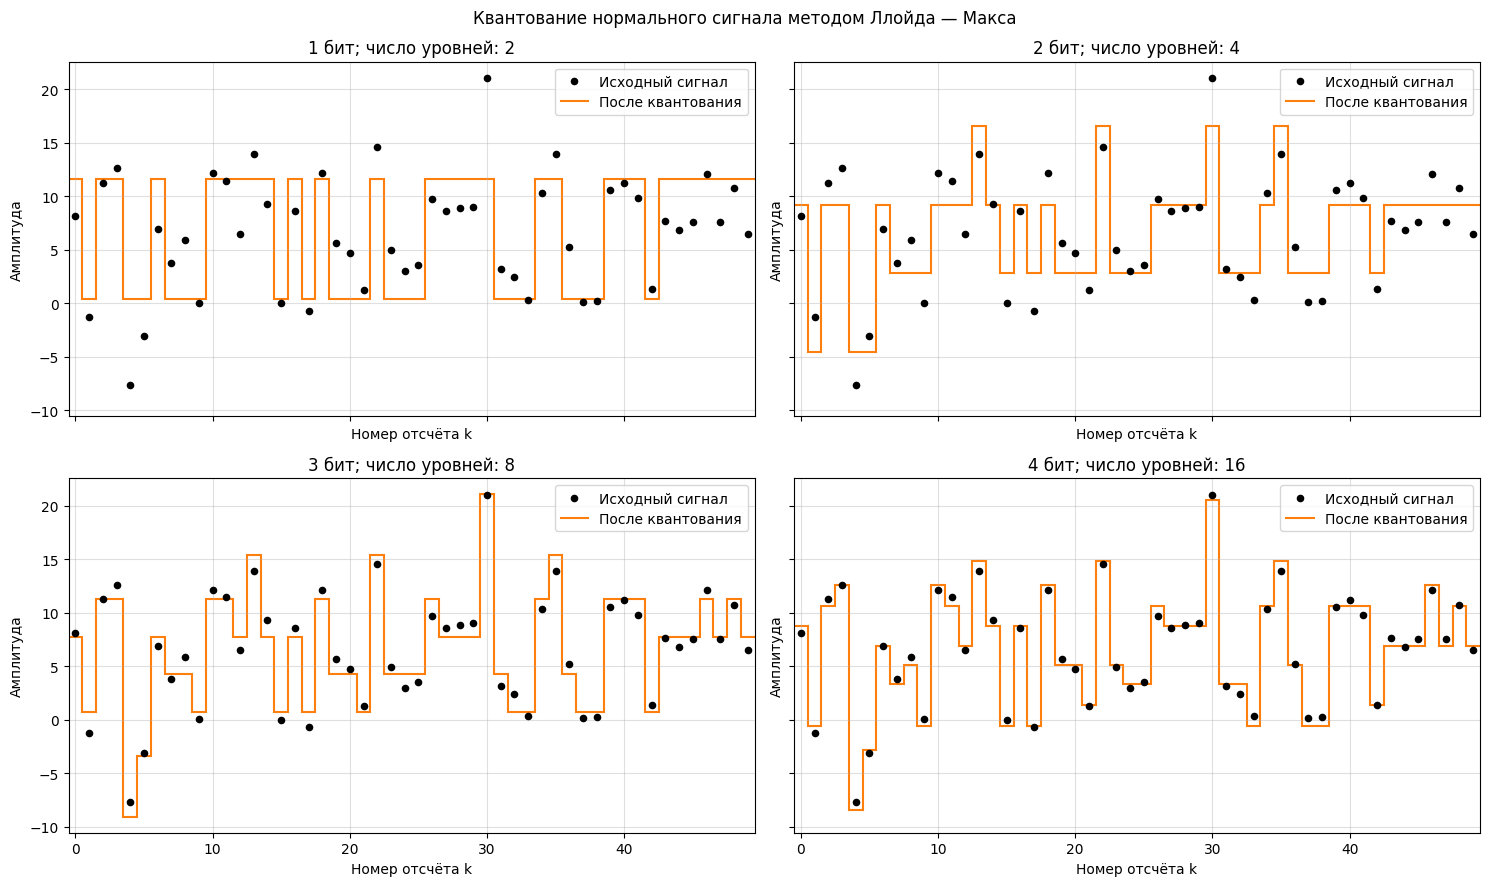

In [25]:
quantized_normal_optimal = {}

n_display = min(50, len(x_normal))
indices_display = np.arange(n_display)
edges = np.arange(n_display + 1) - 0.5

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    sharex=True,
    sharey=True,
)

for bits, ax in zip(range(1, 5), axes.flat):
    parameters = lloyd_max_parameters[bits]

    thresholds = parameters["t"]
    levels = parameters["d"]

    # Исключаем крайние границы -inf и +inf.
    internal_thresholds = thresholds[1:-1]

    # Находим номер интервала для каждого отсчёта.
    # При совпадении с порогом выбираем интервал справа.
    interval_indices = np.searchsorted(
        internal_thresholds,
        x_normal,
        side="right",
    )

    # Заменяем каждый отсчёт уровнем его интервала.
    x_quantized = levels[interval_indices]

    quantized_normal_optimal[bits] = {
        "x": x_quantized,
        "t": thresholds,
        "d": levels,
    }

    ax.scatter(
        indices_display,
        x_normal[:n_display],
        color="black",
        s=20,
        zorder=3,
        label="Исходный сигнал",
    )

    ax.stairs(
        x_quantized[:n_display],
        edges,
        baseline=None,
        color="C1",
        linewidth=1.5,
        label="После квантования",
    )

    ax.set_title(f"{bits} бит; число уровней: {len(levels)}")
    ax.set_xlabel("Номер отсчёта k")
    ax.set_ylabel("Амплитуда")
    ax.set_xlim(-0.5, n_display - 0.5)
    ax.grid(True, alpha=0.4)
    ax.legend()

plt.suptitle("Квантование нормального сигнала методом Ллойда — Макса")
plt.tight_layout()
plt.show()

### Задание 8. Оценка качества оптимального квантования

Для квантования Ллойда — Макса с разрядностью от 1 до 4 бит
вычислить выборочный средний квадрат ошибки и отношение
сигнал/шум. Построить их зависимости от разрядности.

Ошибка квантования каждого отсчёта:

$$
e(k)=x(k)-\hat{x}(k).
$$

Выборочный средний квадрат ошибки:

$$
D=\frac{1}{n}\sum_{k=0}^{n-1}e^2(k).
$$

Средний квадрат исходного сигнала:

$$
P_x=\frac{1}{n}\sum_{k=0}^{n-1}x^2(k).
$$

Отношение сигнал/шум:

$$
\mathrm{SNR}
=20\log_{10}\frac{\sqrt{P_x}}{\sqrt{D}}
=10\log_{10}\frac{P_x}{D}.
$$

Вычисления выполняются по всем отсчётам одной и той же
последовательности для каждой разрядности.

При увеличении числа уровней ожидается уменьшение среднего
квадрата ошибки и увеличение отношения сигнал/шум.

Средний квадрат сигнала: 79.967744

Биты |  Средний квадрат ошибки |    SNR, дБ
---------------------------------------------
   1 |               16.607159 |      6.826
   2 |                5.023632 |     12.019
   3 |                1.443815 |     17.434
   4 |                0.383478 |     23.192


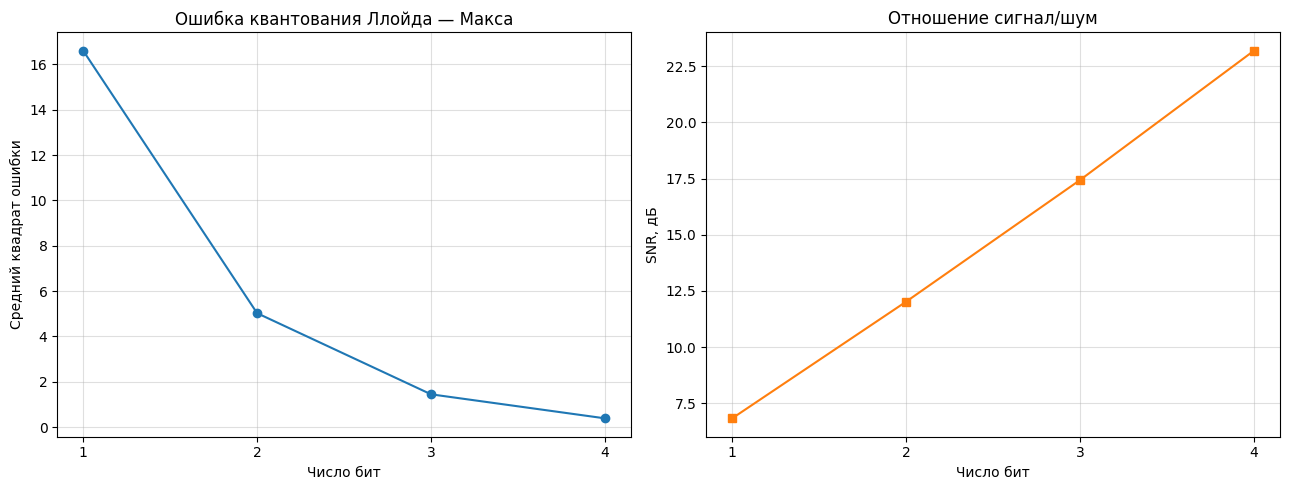

In [26]:
bits_normal = np.arange(1, 5)

mse_normal_optimal = []
snr_normal_optimal = []

# Средний квадрат исходного сигнала, включая ненулевое среднее.
signal_power_normal = np.mean(x_normal**2)

print(f"Средний квадрат сигнала: {signal_power_normal:.6f}\n")
print(f"{'Биты':>4} | {'Средний квадрат ошибки':>23} | {'SNR, дБ':>10}")
print("-" * 45)

for bits in bits_normal:
    x_quantized = quantized_normal_optimal[bits]["x"]

    error = x_normal - x_quantized
    mse = np.mean(error**2)

    snr = (
        10 * np.log10(signal_power_normal / mse)
        if mse > 0
        else np.inf
    )

    mse_normal_optimal.append(mse)
    snr_normal_optimal.append(snr)

    print(f"{bits:4d} | {mse:23.6f} | {snr:10.3f}")

mse_normal_optimal = np.array(mse_normal_optimal)
snr_normal_optimal = np.array(snr_normal_optimal)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(bits_normal, mse_normal_optimal, "o-", color="C0")
axes[0].set_title("Ошибка квантования Ллойда — Макса")
axes[0].set_xlabel("Число бит")
axes[0].set_ylabel("Средний квадрат ошибки")

axes[1].plot(bits_normal, snr_normal_optimal, "s-", color="C1")
axes[1].set_title("Отношение сигнал/шум")
axes[1].set_xlabel("Число бит")
axes[1].set_ylabel("SNR, дБ")

for ax in axes:
    ax.set_xticks(bits_normal)
    ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

### Задание 9. Сравнение равномерного и оптимального квантования

Выполнить равномерное квантование нормального сигнала
с разрядностью от 1 до 4 бит на интервале
$[m-3\sigma,\;m+3\sigma)$.

Значения вне этого интервала заменять ближайшим крайним
уровнем квантования. Вычислить средний квадрат ошибки и SNR.
Сравнить результаты с квантованием Ллойда — Макса.

Для варианта 6:

$$
m=6,\qquad \sigma=7.
$$

Границы интервала квантования:

$$
a=m-3\sigma=-15,\qquad c=m+3\sigma=27.
$$

Число уровней и шаг квантования:

$$
L=2^b,\qquad q=\frac{c-a}{L}=\frac{42}{2^b}.
$$

Сначала определяем номер интервала:

$$
i=\left\lfloor\frac{x-a}{q}\right\rfloor.
$$

Ограничиваем индекс диапазоном от 0 до L−1:

$$
i_{\mathrm{огр}}=\min\bigl(\max(i,0),L-1\bigr).
$$

Квантованное значение равно середине выбранного интервала:

$$
\hat{x}=a+\left(i_{\mathrm{огр}}+\frac12\right)q.
$$

Таким образом, значения ниже a заменяются уровнем a+q/2,
а значения не ниже c — уровнем c−q/2.

Для каждого числа бит вычисляем:

$$
D=\frac{1}{n}\sum_{k=0}^{n-1}(x(k)-\hat{x}(k))^2,
$$

$$
\mathrm{SNR}
=10\log_{10}
\frac{\frac{1}{n}\sum_{k=0}^{n-1}x^2(k)}{D}.
$$

Для обоих методов используются одни и те же исходные отсчёты.

Интервал квантования: [-15, 27)
Отсчётов вне интервала: 0 из 500

Биты | MSE равномерное |  MSE Ллойд–Макс | SNR равн., дБ |  SNR Л–М, дБ
---------------------------------------------------------------------------
   1 |       43.165765 |       16.607159 |         2.678 |        6.826
   2 |        9.309080 |        5.023632 |         9.340 |       12.019
   3 |        2.162356 |        1.443815 |        15.680 |       17.434
   4 |        0.583229 |        0.383478 |        21.371 |       23.192


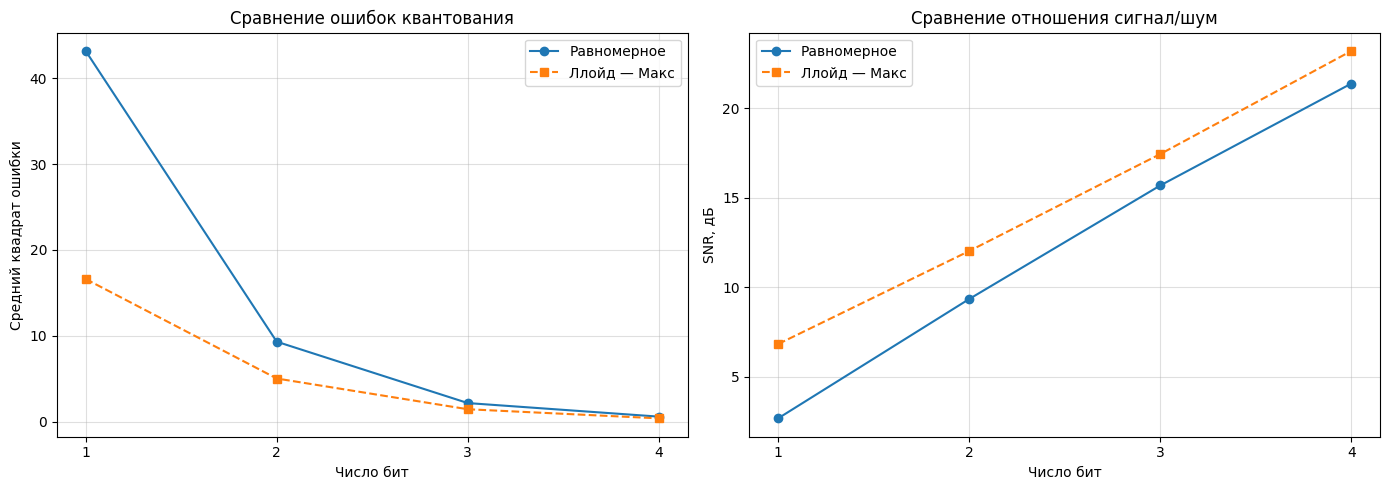

In [28]:
a = m - 3 * sigma   # -15
c = m + 3 * sigma   # 27

bits_normal = np.arange(1, 5)

quantized_normal_uniform = {}
mse_normal_uniform = []
snr_normal_uniform = []

signal_power_normal = np.mean(x_normal**2)

outside = np.count_nonzero((x_normal < a) | (x_normal >= c))
print(f"Интервал квантования: [{a}, {c})")
print(f"Отсчётов вне интервала: {outside} из {len(x_normal)}")

for bits in bits_normal:
    n_levels = 2**bits
    q = (c - a) / n_levels

    # Номер интервала для каждого исходного отсчёта.
    indices = np.floor((x_normal - a) / q).astype(int)

    # Насыщение: ограничиваем индексы крайними уровнями.
    indices = np.clip(indices, 0, n_levels - 1)

    x_quantized = a + (indices + 0.5) * q

    quantized_normal_uniform[bits] = {
        "x": x_quantized,
        "q": q,
    }

    # Ошибку считаем относительно исходного, необрезанного сигнала.
    mse = np.mean((x_normal - x_quantized)**2)
    snr = (
        10 * np.log10(signal_power_normal / mse)
        if mse > 0
        else np.inf
    )

    mse_normal_uniform.append(mse)
    snr_normal_uniform.append(snr)

mse_normal_uniform = np.array(mse_normal_uniform)
snr_normal_uniform = np.array(snr_normal_uniform)

# Таблица сравнения с результатами задания 8.
print(
    f"\n{'Биты':>4} | {'MSE равномерное':>15} | {'MSE Ллойд–Макс':>15} | "
    f"{'SNR равн., дБ':>13} | {'SNR Л–М, дБ':>12}"
)
print("-" * 75)

for i, bits in enumerate(bits_normal):
    print(
        f"{bits:4d} | "
        f"{mse_normal_uniform[i]:15.6f} | "
        f"{mse_normal_optimal[i]:15.6f} | "
        f"{snr_normal_uniform[i]:13.3f} | "
        f"{snr_normal_optimal[i]:12.3f}"
    )

# Сравнение среднего квадрата ошибки и SNR.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    bits_normal, mse_normal_uniform, "o-",
    label="Равномерное",
)
axes[0].plot(
    bits_normal, mse_normal_optimal, "s--",
    label="Ллойд — Макс",
)
axes[0].set_title("Сравнение ошибок квантования")
axes[0].set_ylabel("Средний квадрат ошибки")

axes[1].plot(
    bits_normal, snr_normal_uniform, "o-",
    label="Равномерное",
)
axes[1].plot(
    bits_normal, snr_normal_optimal, "s--",
    label="Ллойд — Макс",
)
axes[1].set_title("Сравнение отношения сигнал/шум")
axes[1].set_ylabel("SNR, дБ")

for ax in axes:
    ax.set_xlabel("Число бит")
    ax.set_xticks(bits_normal)
    ax.grid(True, alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.show()